### Task 1: Designing a Heuristic for a Warehouse Robot

In [1]:
import math
import networkx as nx
import matplotlib.pyplot as plt


# 1. Coordinates of warehouse locations

locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6)
}


# 2. Weighted warehouse graph

warehouse_graph = {
    "Receiving_Area": {
        "Storage_A": 2.2,
        "Storage_B": 4.1
    },

    "Storage_A": {
        "Sorting_Area": 2.2
    },

    "Storage_B": {
        "Inspection_Area": 5.0,
        "Sorting_Area": 6.0
    },

    "Sorting_Area": {
        "Inspection_Area": 3.2,
        "Packing_Station": 5.0
    },

    "Inspection_Area": {
        "Packing_Station": 2.2
    },

    "Packing_Station": {}
}


# 3. Euclidean heuristic


def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    distance = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    return distance



# 4. Calculate heuristic values

goal = "Packing_Station"

print("Heuristic Values")
print("----------------")

for location in locations:
    h = heuristic(location, goal)
    print(f"{location:20s} h(n) = {h:.2f}")

# 5. Why Euclidean distance?
print("\nWhy Euclidean distance?")
print("The robot moves between locations that have (x, y) coordinates, so the straight line")
print("distance is the shortest possible distance to the Packing Station. The real path can")
print("never be shorter than a straight line, so h(n) does not overestimate the cost.")

Heuristic Values
----------------
Receiving_Area       h(n) = 9.22
Storage_A            h(n) = 7.07
Storage_B            h(n) = 6.32
Sorting_Area         h(n) = 5.00
Inspection_Area      h(n) = 2.24
Packing_Station      h(n) = 0.00

Why Euclidean distance?
The robot moves between locations that have (x, y) coordinates, so the straight line
distance is the shortest possible distance to the Packing Station. The real path can
never be shorter than a straight line, so h(n) does not overestimate the cost.


#### NetworkX visualization: Since Task 1 does not ask GBFS/A* to find a path, you are supposed highlight the actual minimum-cost path merely for visualization:

In [2]:
# 5. Create NetworkX graph

G = nx.DiGraph()

for node, neighbors in warehouse_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

# 6. Find minimum-cost path
## The primary function to find the shortest path in the Python networkx library
### 1. Unweighted shortest path (ignores 'weight', finds fewest number of edges)
### 2. Weighted shortest path (minimizes the sum of the 'weight' attribute)
solution_path = nx.shortest_path( # reaturn the path e.g. A → B → C
    G,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

solution_cost = nx.shortest_path_length( #return the numeric value
    G,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

print("\nMinimum cost path:")
print(" -> ".join(solution_path))
print(f"Total cost: {solution_cost:.2f}")


Minimum cost path:
Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 9.40


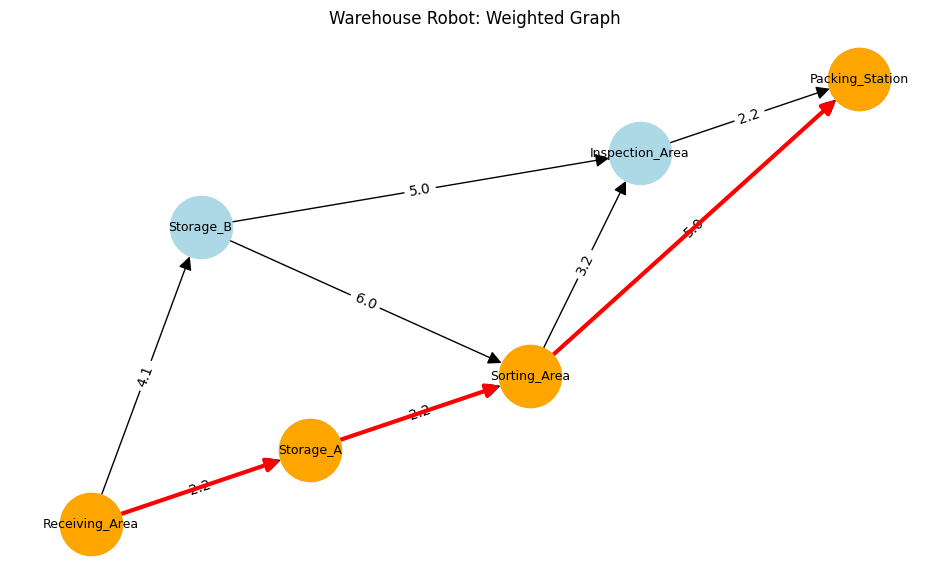

In [3]:
# 7. Visualize graph

pos = locations

plt.figure(figsize=(12, 7))

# draw all nodes and edges
nx.draw_networkx_nodes(G, pos, node_color="lightseagreen", node_size=2000)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=2000)
nx.draw_networkx_labels(G, pos, font_size=9)

# draw edge weights
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

# highlight solution path
path_edges = list(zip(solution_path, solution_path[1:]))
nx.draw_networkx_nodes(G, pos, nodelist=solution_path, node_color="coral", node_size=2000)
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True, arrowsize=20, node_size=2000)


plt.title("Warehouse Robot: Weighted Graph")
plt.axis("off")
plt.show()

In [4]:
# 8. Verify heuristic condition

print("\nHeuristic Condition Verification")
print("***********************************")

for node in warehouse_graph:

    for neighbor, cost in warehouse_graph[node].items():

        h_n = heuristic(node, goal)
        h_m = heuristic(neighbor, goal)
        right_side = cost + h_m

        if h_n <= right_side:
            result = "Satisfied"
        else:
            result = "Not Satisfied"

        print(f"{node} -> {neighbor}: {h_n:.2f} <= {cost} + {h_m:.2f} = {right_side:.2f}  {result}")


Heuristic Condition Verification
***********************************
Receiving_Area -> Storage_A: 9.22 <= 2.2 + 7.07 = 9.27  Satisfied
Receiving_Area -> Storage_B: 9.22 <= 4.1 + 6.32 = 10.42  Satisfied
Storage_A -> Sorting_Area: 7.07 <= 2.2 + 5.00 = 7.20  Satisfied
Storage_B -> Inspection_Area: 6.32 <= 5.0 + 2.24 = 7.24  Satisfied
Storage_B -> Sorting_Area: 6.32 <= 6.0 + 5.00 = 11.00  Satisfied
Sorting_Area -> Inspection_Area: 5.00 <= 3.2 + 2.24 = 5.44  Satisfied
Sorting_Area -> Packing_Station: 5.00 <= 5.0 + 0.00 = 5.00  Satisfied
Inspection_Area -> Packing_Station: 2.24 <= 2.2 + 0.00 = 2.20  Not Satisfied


write down your observation in one line:

Observation: The heuristic condition holds for every edge except Inspection_Area -> Packing_Station (2.24 > 2.20), and that happens only because the edge cost 2.2 is a rounded value of the real distance 2.236.

### Task 2: Greedy Best-First Search for Airport Baggage Handling

In [5]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# 1. Airport coordinates

locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6)
}

# 2. Weighted graph


airport_graph = {
    "Baggage_Area": {
        "Security": 2.2,
        "Checkpoint": 4.1
    },

    "Security": {
        "Food_Court": 2.2
    },

    "Checkpoint": {
        "Terminal_Hall": 5.0
    },

    "Food_Court": {
        "Terminal_Hall": 3.2,
        "Departure_Gate": 6.0
    },

    "Terminal_Hall": {
        "Departure_Gate": 3.2
    },

    "Departure_Gate": {}
}

# 3. Euclidean heuristic


def heuristic(current, goal):

    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)


# 4. GBFS


def greedy_best_first_search(start, goal, graph):

    # priority queue stores (h(n), node)
    frontier = []
    heapq.heappush(frontier, (heuristic(start, goal), start))

    came_from = {start: None}
    explored = set()
    expansion_order = []

    while frontier:

        h, current = heapq.heappop(frontier)

        if current in explored:
            continue

        explored.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor in graph[current]:
            if neighbor not in explored and neighbor not in came_from:
                came_from[neighbor] = current
                heapq.heappush(frontier, (heuristic(neighbor, goal), neighbor))

    if goal not in came_from:
        return None, 0, expansion_order

    # Reconstruct path
    path = []
    node = goal
    while node is not None:
        path.append(node)
        node = came_from[node]
    path.reverse()

    # Calculate actual path cost
    total_cost = 0
    for i in range(len(path) - 1):
        total_cost += graph[path[i]][path[i + 1]]

    return path, total_cost, expansion_order


# 5. Run GBFS


start = "Baggage_Area"
goal = "Departure_Gate"

path, total_cost, expansion_order = greedy_best_first_search(start, goal, airport_graph)

print("GBFS")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")

print("\nHeuristic values:")
for node in locations:
    print(f"{node:16s} h(n) = {heuristic(node, goal):.2f}")

# Explanation
print("\nWhy GBFS chose this order:")
print("From Baggage_Area, Checkpoint (h = 7.28) looks closer to the gate than Security (h = 7.81),")
print("so GBFS picks Checkpoint. Then Terminal_Hall (h = 3.16) is the only neighbour, and from there")
print("the Departure_Gate (h = 0) is reached. GBFS only looks at h(n) and ignores the cost already")
print("travelled, so it took a path with cost 12.30 while the cheaper path through Security and")
print("Food_Court costs only 10.40.")

GBFS
--------------------------------
Expansion order:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Solution path:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Total path cost: 12.30

Heuristic values:
Baggage_Area     h(n) = 10.00
Security         h(n) = 7.81
Checkpoint       h(n) = 7.28
Food_Court       h(n) = 5.66
Terminal_Hall    h(n) = 3.16
Departure_Gate   h(n) = 0.00

Why GBFS chose this order:
From Baggage_Area, Checkpoint (h = 7.28) looks closer to the gate than Security (h = 7.81),
so GBFS picks Checkpoint. Then Terminal_Hall (h = 3.16) is the only neighbour, and from there
the Departure_Gate (h = 0) is reached. GBFS only looks at h(n) and ignores the cost already
travelled, so it took a path with cost 12.30 while the cheaper path through Security and
Food_Court costs only 10.40.


#### NetworkX visualization

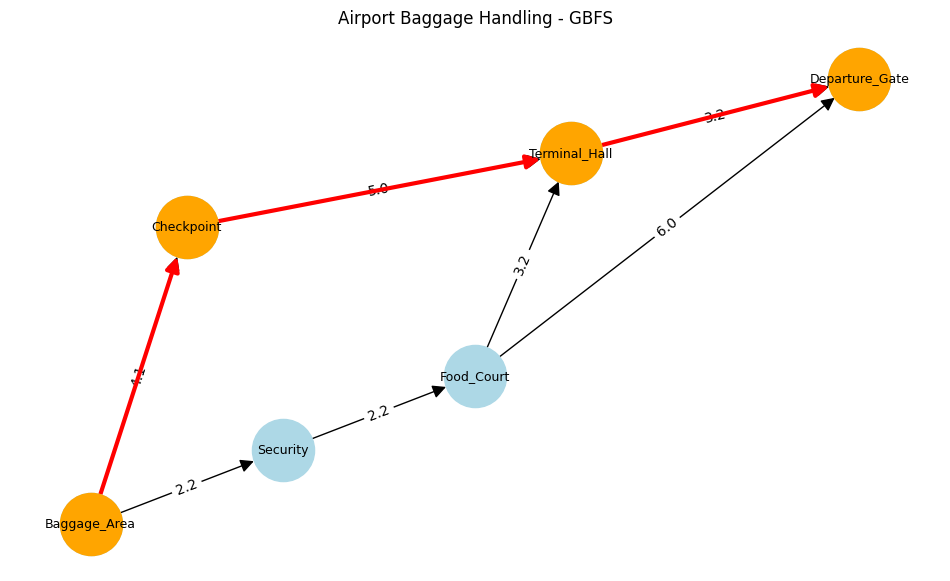

In [6]:
# 6. NetworkX visualization

G = nx.DiGraph()

for node, neighbors in airport_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)


pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="lightseagreen", node_size=2000)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=2000)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

# highlight GBFS path
path_edges = list(zip(path, path[1:]))
nx.draw_networkx_nodes(G, pos, nodelist=path, node_color="coral", node_size=2000)
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True, arrowsize=20, node_size=2000)

plt.title("Airport Baggage Handling - GBFS")
plt.axis("off")
plt.show()

### Task 3: A* Search for Emergency Supply Robot

In [7]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt


# 1. Hospital coordinates


locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6)
}


# 2. Hospital weighted graph


hospital_graph = {
    "Pharmacy": {
        "Main_Corridor": 2.2,
        "Patient_Wing": 4.1
    },

    "Main_Corridor": {
        "Nursing_Station": 2.2
    },

    "Patient_Wing": {
        "Laboratory": 5.0
    },

    "Nursing_Station": {
        "Laboratory": 3.2,
        "Emergency_Ward": 6.0
    },

    "Laboratory": {
        "Emergency_Ward": 3.2
    },

    "Emergency_Ward": {}
}

# 3. Euclidean heuristic


def heuristic(current, goal):

    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

# 4. Path reconstruction

def reconstruct_path(came_from, current):

    path = []
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()
    return path

# 5. A* Search
def a_star_search(start, goal, graph):

    frontier = []
    heapq.heappush(frontier, (heuristic(start, goal), start))  # (f(n), node)

    came_from = {start: None}
    g_cost = {start: 0}
    explored = set()
    expansion_order = []

    while frontier:

        f, current = heapq.heappop(frontier)

        if current in explored:
            continue

        explored.add(current)
        expansion_order.append(current)

        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, g_cost[goal], expansion_order, g_cost

        for neighbor, cost in graph[current].items():

            tentative_g = g_cost[current] + cost

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                f_value = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(frontier, (f_value, neighbor))

    return None, 0, expansion_order, g_cost

# 6. Run A*

start = "Pharmacy"
goal = "Emergency_Ward"

path, total_cost, expansion_order, g_cost = a_star_search(start, goal, hospital_graph)

print("A* Search")
print("--------------------------------")

print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")

A* Search
--------------------------------
Expansion order:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Solution path:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Total path cost: 10.40


#### g(n), h(n), f(n) table

In [8]:
# you may also replace it with dataframe it is completely your own choice

print("\nA* Node Information")
print("*********************")
print(
    f"{'Node':20s}" #'Node' → the text to print, 20 → use 20 spaces/characters of width, s → treat it as a string
    f"{'g(n)':>10s}"
    f"{'h(n)':>10s}"
    f"{'f(n)':>10s}"
)

for node in expansion_order:

    g = g_cost[node]
    h = heuristic(node, goal)
    f = g + h

    print(
        f"{node:20s}"
        f"{g:10.2f}"
        f"{h:10.2f}"
        f"{f:10.2f}"
    )

# Comparison of A* and GBFS
print("\nA* vs GBFS:")
print("GBFS would pick Patient_Wing first because its h(n) = 7.28 is smaller than Main_Corridor's 7.81.")
print("A* also adds g(n), so f(Main_Corridor) = 2.2 + 7.81 = 10.01 is smaller than")
print("f(Patient_Wing) = 4.1 + 7.28 = 11.38. Because of g(n), A* goes through Main_Corridor and")
print("Nursing_Station and finds the cheapest path with cost 10.40.")


A* Node Information
*********************
Node                      g(n)      h(n)      f(n)
Pharmacy                  0.00     10.00     10.00
Main_Corridor             2.20      7.81     10.01
Nursing_Station           4.40      5.66     10.06
Emergency_Ward           10.40      0.00     10.40

A* vs GBFS:
GBFS would pick Patient_Wing first because its h(n) = 7.28 is smaller than Main_Corridor's 7.81.
A* also adds g(n), so f(Main_Corridor) = 2.2 + 7.81 = 10.01 is smaller than
f(Patient_Wing) = 4.1 + 7.28 = 11.38. Because of g(n), A* goes through Main_Corridor and
Nursing_Station and finds the cheapest path with cost 10.40.


#### NetworkX visualization

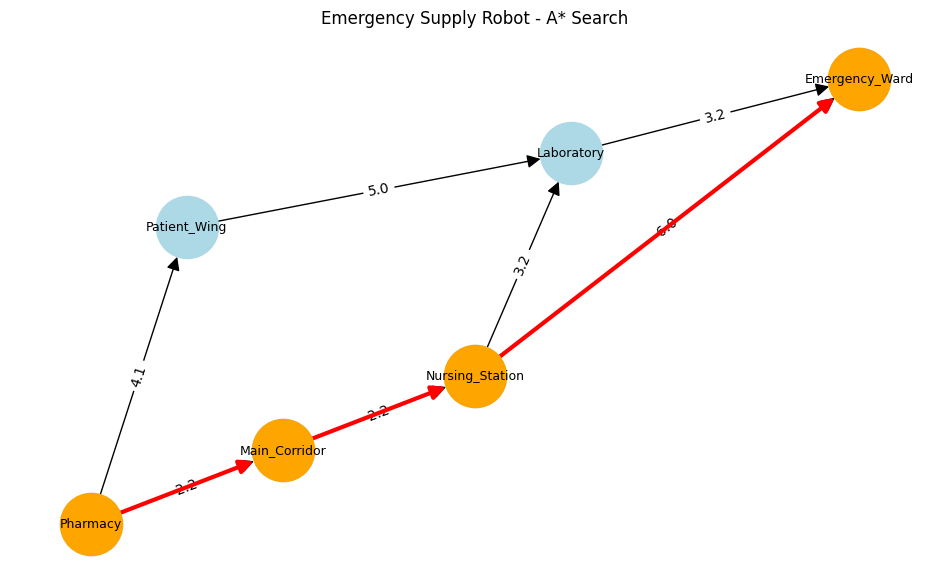

In [9]:
# 7. NetworkX visualization
G = nx.DiGraph()

for node, neighbors in hospital_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)


pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="lightseagreen", node_size=2000)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=2000)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

# highlight A* path
path_edges = list(zip(path, path[1:]))
nx.draw_networkx_nodes(G, pos, nodelist=path, node_color="coral", node_size=2000)
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True, arrowsize=20, node_size=2000)

plt.title("Emergency Supply Robot - A* Search")
plt.axis("off")
plt.show()

GBFS would primarily ask:

"Which node appears closest to the Emergency Ward?"

A* instead asks:

"Considering both the cost already travelled and the estimated remaining cost, which node has the lowest estimated total cost?"

### Task 4: Weighted A* for Autonomous Delivery Drone

In [10]:
import math
import heapq
import pandas as pd

# 1. Location Coordinates

locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (8, 6)
}

# 2. Weighted Graph

graph = {
    "Distribution_Center": {
        "Zone_A": 2.2,
        "Zone_B": 3.0
    },

    "Zone_A": {
        "Zone_C": 2.2
    },

    "Zone_B": {
        "Zone_D": 5.0
    },

    "Zone_C": {
        "Zone_D": 3.2,
        "Customer_Building": 6.0
    },

    "Zone_D": {
        "Customer_Building": 3.2
    },

    "Customer_Building": {}
}

# 3. Euclidean Heuristic

def heuristic(node, goal):

    x1, y1 = locations[node]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

# 4. Display Heuristic Values
goal = "Customer_Building"

heuristic_data = []

for node in locations:

    heuristic_data.append({
        "Node": node,
        "h(n)": round(heuristic(node, goal), 2)
    })

heuristic_df = pd.DataFrame(heuristic_data)

print("Heuristic Values:")
print(heuristic_df.to_string(index=False))

# 5. Weighted A* Search
# f(n) = g(n) + w * h(n)


def weighted_a_star(start, goal, graph, weight):

    frontier = []
    heapq.heappush(frontier, (weight * heuristic(start, goal), start))

    came_from = {start: None}
    g_cost = {start: 0}
    explored = set()
    expansion_order = []

    while frontier:

        f, current = heapq.heappop(frontier)

        if current in explored:
            continue

        explored.add(current)
        expansion_order.append(current)

        if current == goal:
            path = []
            node = current
            while node is not None:
                path.append(node)
                node = came_from[node]
            path.reverse()
            return path, g_cost[goal], expansion_order

        for neighbor, cost in graph[current].items():

            tentative_g = g_cost[current] + cost

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                f_value = tentative_g + weight * heuristic(neighbor, goal)
                heapq.heappush(frontier, (f_value, neighbor))

    return None, 0, expansion_order

# 6. Run Weighted A* for All Required Weights
start = "Distribution_Center"
goal = "Customer_Building"

weights = [1, 1.5, 2, 3]

results = []

for w in weights:

    path, cost, expansion_order = weighted_a_star(
        start,
        goal,
        graph,
        w
    )

    results.append({
        "Weight": w,
        "Solution Path": " → ".join(path),
        "Total Cost": round(cost, 2),
        "Nodes Expanded": len(expansion_order),
        "Expansion Order": " → ".join(expansion_order)
    })


# 7. Display Results in dataframe

results_df = pd.DataFrame(results)

print("\nWeighted A* Results:")
print(results_df[["Weight", "Solution Path", "Total Cost", "Nodes Expanded"]].to_string(index=False))


# 8. Display Detailed Expansion Orders

print("\nExpansion Orders:")
for r in results:
    print(f"w = {r['Weight']}: {r['Expansion Order']}")


# ***
# Expected Main Results
# ***

# w = 1:
# Distribution_Center → Zone_A → Zone_C → Customer_Building
# Cost = 10.4
#
# w = 1.5:
# Distribution_Center → Zone_A → Zone_C → Customer_Building
# Cost = 10.4
#
# w = 2:
# Distribution_Center → Zone_B → Zone_D → Customer_Building
# Cost = 11.2
#
# w = 3:
# Distribution_Center → Zone_B → Zone_D → Customer_Building
# Cost = 11.2


# 9. Comparison and explanation
print("\nComparison:")
print("For w = 1 and w = 1.5 the search finds the optimal path with cost 10.4.")
print("For w = 2 and w = 3 the heuristic becomes more important than the real cost g(n),")
print("so the search goes towards Zone_B because it looks closer to the goal, and returns a")
print("more expensive path with cost 11.2.")
print("w = 1 expanded 5 nodes, the higher weights expanded only 4 nodes, so a bigger w makes the")
print("search faster but it can lose the optimal answer because w * h(n) can overestimate the cost.")

Heuristic Values:
               Node  h(n)
Distribution_Center 10.00
             Zone_A  7.81
             Zone_B  7.28
             Zone_C  5.66
             Zone_D  3.16
  Customer_Building  0.00

Weighted A* Results:
 Weight                                             Solution Path  Total Cost  Nodes Expanded
    1.0 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               5
    1.5 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               4
    2.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4
    3.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4

Expansion Orders:
w = 1: Distribution_Center → Zone_A → Zone_C → Zone_B → Customer_Building
w = 1.5: Distribution_Center → Zone_A → Zone_C → Customer_Building
w = 2: Distribution_Center → Zone_B → Zone_D → Customer_Building
w = 3: Distribution_Center → Zone_B → Zone_D → Customer_Building

Comparison:
For w

#### NetworkX visualization

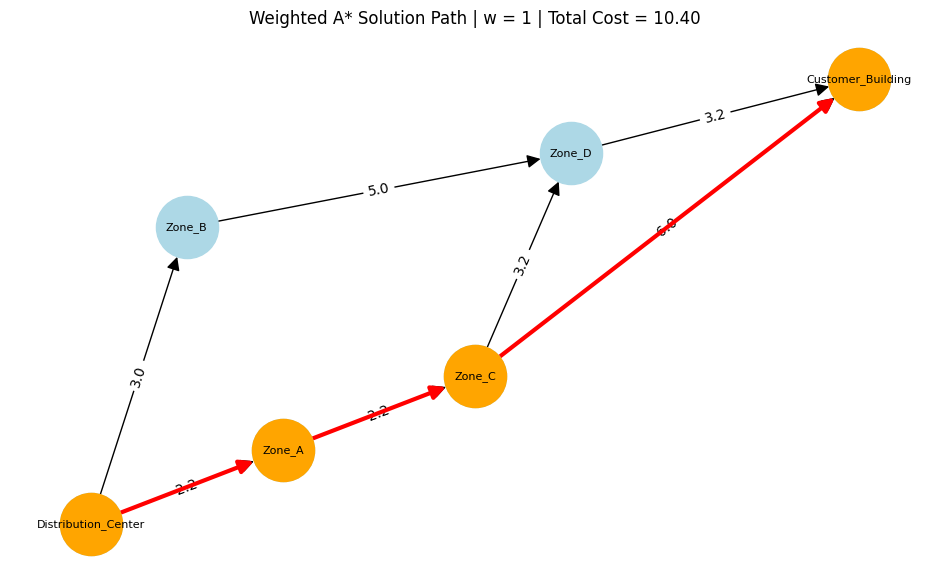

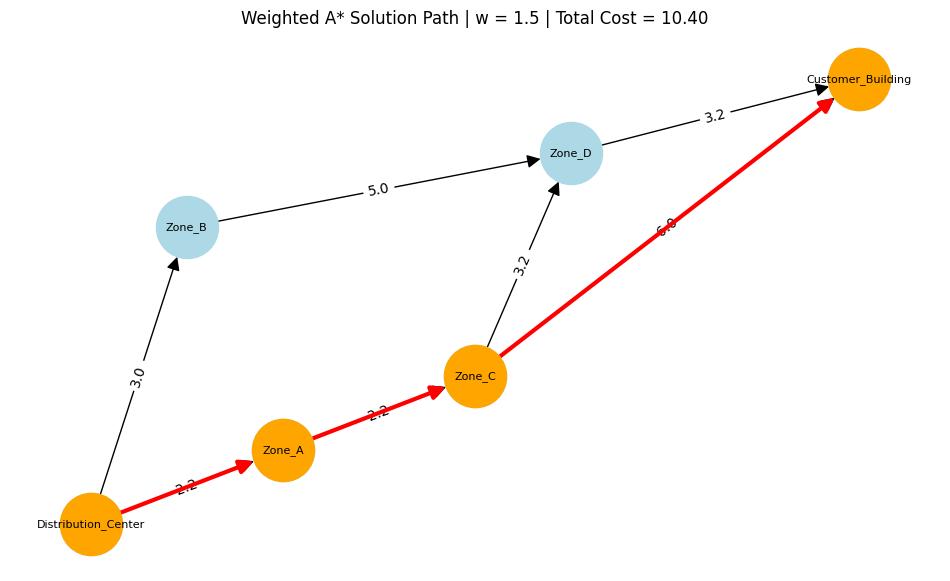

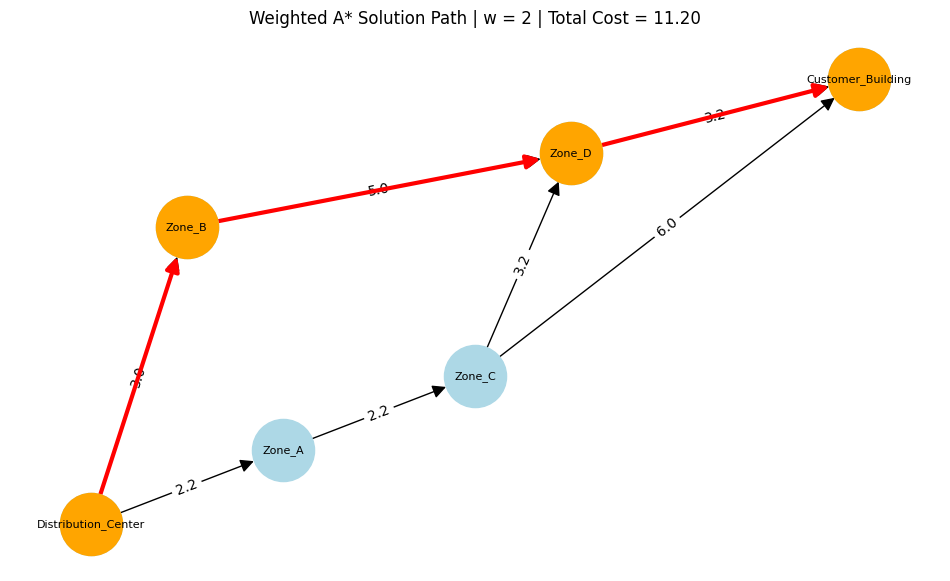

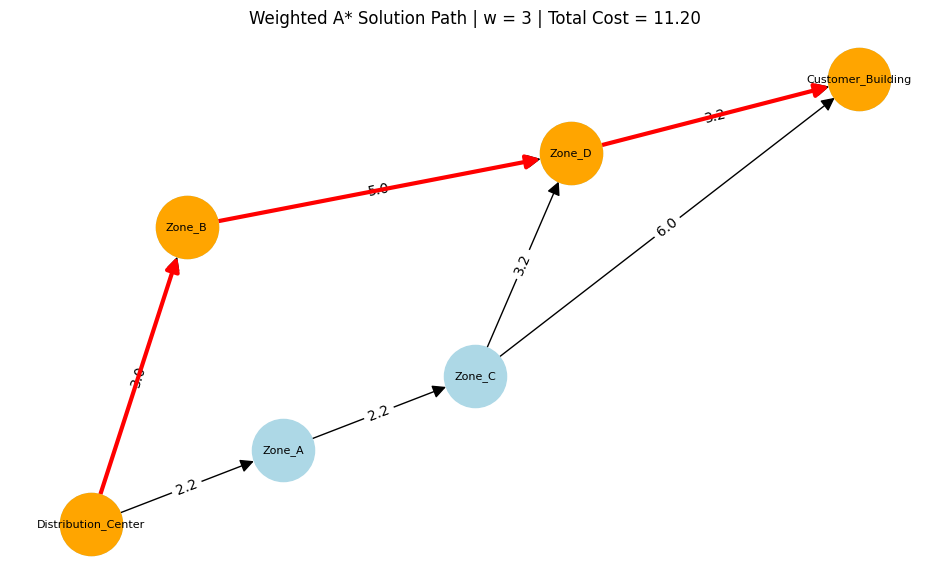

In [11]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Create NetworkX Graph

G = nx.DiGraph()

# Add nodes with their coordinates
for node, position in locations.items():

    G.add_node(
        node,
        pos=position
    )


# Add weighted edges
for node, neighbors in graph.items():

    for neighbor, cost in neighbors.items():

        G.add_edge(node, neighbor, weight=cost)

# 2. Node Positions
pos = locations

# 3. Visualize Weighted A* Result for Each Weight

for w in weights:

    # Run Weighted A*
    path, cost, expansion_order = weighted_a_star(start, goal, graph, w)

    plt.figure(figsize=(12, 7))

    nx.draw_networkx_nodes(G, pos, node_color="lightseagreen", node_size=2000)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=2000)
    nx.draw_networkx_labels(G, pos, font_size=8)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_nodes(G, pos, nodelist=path, node_color="coral", node_size=2000)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True, arrowsize=20, node_size=2000)

    plt.title(
        f"Weighted A* Solution Path | w = {w} | "
        f"Total Cost = {cost:.2f}"
    )

    plt.axis("off")

    plt.show()

#### Expansion order

This means:

In what order did the search algorithm remove/select nodes from the frontier and process them?

For example:

Expanded:
S → A → B → C → D → G

The algorithm may explore some nodes that are ultimately not part of the final route.

#### Solution path

This means:

Which nodes form the final route from start to goal?

For example:

Solution:
S → A → C → G

Here:

Expansion order:  S → A → B → C → D → G
Solution path:    S → A → C → G

### Task 5: Finding a Charging Station Using Multiple Goals

In [12]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# 1. City coordinates

locations = {
    "Current_Location": (0, 0),
    "Junction_A": (2, 1),
    "Junction_B": (1, 4),
    "Junction_C": (4, 2),
    "Junction_D": (5, 5),
    "Charging_North": (8, 7),
    "Charging_Central": (7, 3),
    "Charging_South": (6, -2)
}

# 2. Weighted graph

city_graph = {
    "Current_Location": {
        "Junction_A": 2.2,
        "Junction_B": 4.1
    },

    "Junction_A": {
        "Junction_C": 2.2
    },

    "Junction_B": {
        "Junction_D": 5.0
    },

    "Junction_C": {
        "Junction_D": 3.2,
        "Charging_Central": 4.0,
        "Charging_South": 5.0
    },

    "Junction_D": {
        "Charging_North": 3.2,
        "Charging_Central": 4.0
    },

    "Charging_North": {},
    "Charging_Central": {},
    "Charging_South": {}
}

goals = ["Charging_North", "Charging_Central", "Charging_South"]

# 3. Heuristic = distance to the NEAREST charging station

def distance(a, b):
    x1, y1 = locations[a]
    x2, y2 = locations[b]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)


def heuristic(node, goals):
    return min(distance(node, g) for g in goals)


print("Heuristic values (distance to nearest charging station):")
for node in locations:
    print(f"{node:18s} h(n) = {heuristic(node, goals):.2f}")

Heuristic values (distance to nearest charging station):
Current_Location   h(n) = 6.32
Junction_A         h(n) = 5.00
Junction_B         h(n) = 6.08
Junction_C         h(n) = 3.16
Junction_D         h(n) = 2.83
Charging_North     h(n) = 0.00
Charging_Central   h(n) = 0.00
Charging_South     h(n) = 0.00


#### Part A: Greedy Best-First Search

In [13]:
def reconstruct_path(came_from, current):
    path = []
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()
    return path


def path_cost(path, graph):
    total = 0
    for i in range(len(path) - 1):
        total += graph[path[i]][path[i + 1]]
    return total


def gbfs_multi_goal(start, goals, graph):

    frontier = []
    heapq.heappush(frontier, (heuristic(start, goals), start))

    came_from = {start: None}
    explored = set()
    expansion_order = []

    while frontier:

        h, current = heapq.heappop(frontier)

        if current in explored:
            continue

        explored.add(current)
        expansion_order.append(current)

        # stop when ANY charging station is reached
        if current in goals:
            path = reconstruct_path(came_from, current)
            return current, path, path_cost(path, graph), expansion_order

        for neighbor in graph[current]:
            if neighbor not in explored and neighbor not in came_from:
                came_from[neighbor] = current
                heapq.heappush(frontier, (heuristic(neighbor, goals), neighbor))

    return None, None, 0, expansion_order


start = "Current_Location"

gbfs_station, gbfs_path, gbfs_cost, gbfs_order = gbfs_multi_goal(start, goals, city_graph)

print("GBFS")
print("--------------------------------")
print("Expansion order:", " -> ".join(gbfs_order))
print("Charging station reached:", gbfs_station)
print("Solution path:", " -> ".join(gbfs_path))
print(f"Total path cost: {gbfs_cost:.2f}")

GBFS
--------------------------------
Expansion order: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Charging station reached: Charging_Central
Solution path: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Total path cost: 8.40


#### Part B: A* Search

In [14]:
def a_star_multi_goal(start, goals, graph):

    frontier = []
    heapq.heappush(frontier, (heuristic(start, goals), start))

    came_from = {start: None}
    g_cost = {start: 0}
    explored = set()
    expansion_order = []

    while frontier:

        f, current = heapq.heappop(frontier)

        if current in explored:
            continue

        explored.add(current)
        expansion_order.append(current)

        if current in goals:
            path = reconstruct_path(came_from, current)
            return current, path, g_cost[current], expansion_order

        for neighbor, cost in graph[current].items():

            tentative_g = g_cost[current] + cost

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                heapq.heappush(frontier, (tentative_g + heuristic(neighbor, goals), neighbor))

    return None, None, 0, expansion_order


astar_station, astar_path, astar_cost, astar_order = a_star_multi_goal(start, goals, city_graph)

print("A* Search")
print("--------------------------------")
print("Expansion order:", " -> ".join(astar_order))
print("Charging station reached:", astar_station)
print("Solution path:", " -> ".join(astar_path))
print(f"Total path cost: {astar_cost:.2f}")

A* Search
--------------------------------
Expansion order: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Charging station reached: Charging_Central
Solution path: Current_Location -> Junction_A -> Junction_C -> Charging_Central
Total path cost: 8.40


#### Part C: Comparison

In [15]:
comparison = pd.DataFrame({
    "Measure": ["Charging station reached", "Solution path", "Total path cost", "Number of nodes expanded"],
    "GBFS": [gbfs_station, " -> ".join(gbfs_path), round(gbfs_cost, 2), len(gbfs_order)],
    "A*": [astar_station, " -> ".join(astar_path), round(astar_cost, 2), len(astar_order)]
})

print(comparison.to_string(index=False))

                 Measure                                                             GBFS                                                               A*
Charging station reached                                                 Charging_Central                                                 Charging_Central
           Solution path Current_Location -> Junction_A -> Junction_C -> Charging_Central Current_Location -> Junction_A -> Junction_C -> Charging_Central
         Total path cost                                                              8.4                                                              8.4
Number of nodes expanded                                                                4                                                                4


#### NetworkX visualization

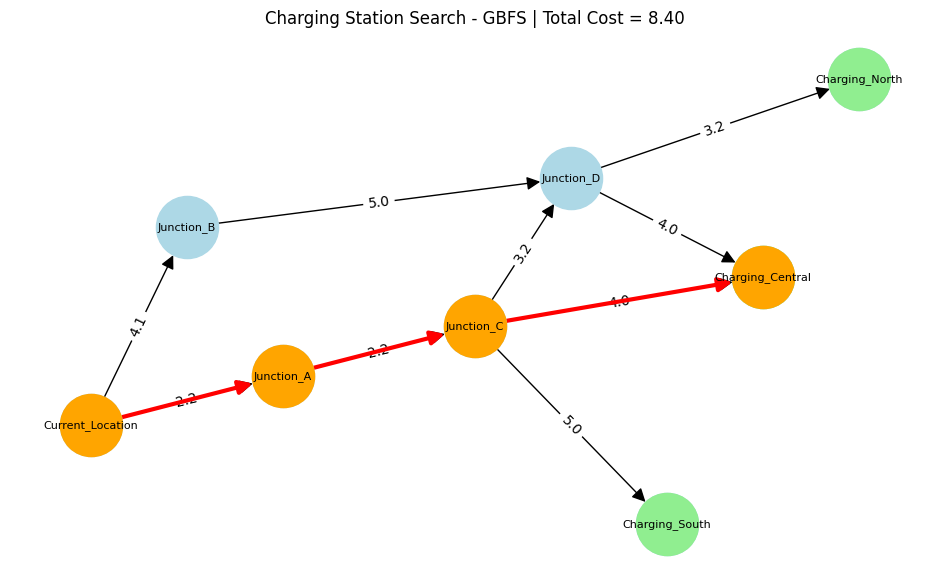

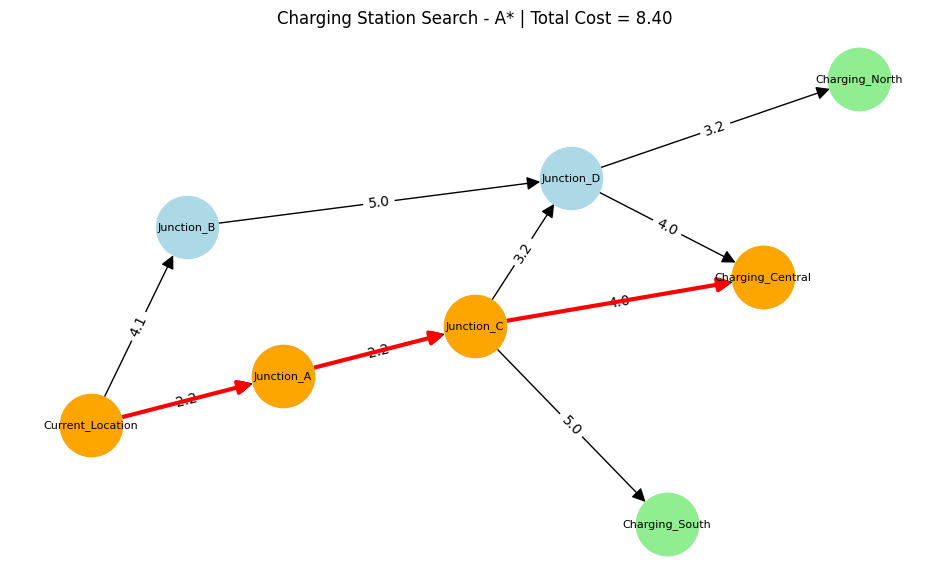

In [16]:
G = nx.DiGraph()

for node, neighbors in city_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

pos = locations

for name, path, cost in [("GBFS", gbfs_path, gbfs_cost), ("A*", astar_path, astar_cost)]:

    plt.figure(figsize=(12, 7))

    nx.draw_networkx_nodes(G, pos, node_color="lightseagreen", node_size=2000)
    nx.draw_networkx_nodes(G, pos, nodelist=goals, node_color="lightgreen", node_size=2000)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=2000)
    nx.draw_networkx_labels(G, pos, font_size=8)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_nodes(G, pos, nodelist=path, node_color="coral", node_size=2000)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True, arrowsize=20, node_size=2000)

    plt.title(f"Charging Station Search - {name} | Total Cost = {cost:.2f}")
    plt.axis("off")
    plt.show()

In [17]:
# Short analysis
print("Analysis:")
print("In this graph both GBFS and A* reached Charging_Central with cost 8.40 and expanded 4 nodes.")
print("GBFS only uses h(n), so it just goes to the node that looks nearest to a charging station.")
print("A* uses g(n) + h(n), so it also checks how much it has already travelled. Here the node that")
print("looked closest was also on the cheapest path, so both gave the same answer. In other graphs")
print("GBFS can pick a node that looks close but costs more, and then the two algorithms will differ.")

Analysis:
In this graph both GBFS and A* reached Charging_Central with cost 8.40 and expanded 4 nodes.
GBFS only uses h(n), so it just goes to the node that looks nearest to a charging station.
A* uses g(n) + h(n), so it also checks how much it has already travelled. Here the node that
looked closest was also on the cheapest path, so both gave the same answer. In other graphs
GBFS can pick a node that looks close but costs more, and then the two algorithms will differ.
